# HeartGuard AI — Weeks 4–8: features, baseline, Voting Classifier, tuning, threshold

**How to use:** Restart the kernel, then *Run All*. Cells depend on the ones above them, so keep the order.
The tuning cells (Week 7) take several minutes. Every result file is written to `training/artifacts/`.

| Section | PRD week | Output |
|---|---|---|
| 0. Setup | – | data, seeds, helper functions |
| 1. Leakage check | 4 | proof that preprocessing is fit on training data only |
| 2. Baseline | 5 | `baseline_cv_*.csv/json` |
| 3. Candidates | 6 | `week6_candidates_cv_folds.csv` |
| 4. Tuning | 7 | `week7_soft_*`, `oof_proba_soft.npy` |
| 5. Threshold + evaluation | 8 | `eval_curves.png`, `week8_*`, `models/model_m1.0.0.*` |

## 0. Setup

In [12]:
import sys, json, time, hashlib, datetime
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "data/raw/heart_disease.csv").exists())
sys.path.insert(0, str(REPO_ROOT))
ARTIFACTS = REPO_ROOT / "training" / "artifacts"

from training.src.features.preprocessing import load_xy, build_preprocessor

SEED = 42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

df = pd.read_csv(REPO_ROOT / "data/raw/heart_disease.csv")
X, y = load_xy(df)                       # drops the 1 duplicate row
print(X.shape, y.value_counts().to_dict())   # expect (302, 13)
df.head()

(302, 13) {1: 164, 0: 138}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [13]:
def make(clf):
    """Preprocessing + classifier in one pipeline, so preprocessing is re-fit inside every CV fold."""
    return Pipeline([("prep", build_preprocessor()), ("clf", clf)])


def evaluate_cv(model, name, threshold=0.5):
    """Stratified 5-fold CV. Returns one row of metrics per fold."""
    rows = []
    for fold, (tr, va) in enumerate(skf.split(X, y), 1):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        if hasattr(m, "predict_proba"):
            proba = m.predict_proba(X.iloc[va])[:, 1]
            pred = (proba >= threshold).astype(int)
            auc = roc_auc_score(y.iloc[va], proba)
        else:                              # hard voting has labels only
            pred = m.predict(X.iloc[va]); auc = np.nan
        tn, fp, fn, tp = confusion_matrix(y.iloc[va], pred, labels=[0, 1]).ravel()
        rows.append(dict(model=name, fold=fold, sensitivity=tp / (tp + fn),
                         specificity=tn / (tn + fp), f1=f1_score(y.iloc[va], pred), roc_auc=auc))
    return pd.DataFrame(rows)


def summarise(folds):
    return (folds.groupby("model")[["sensitivity", "specificity", "f1", "roc_auc"]]
                 .agg(["mean", "std"]).round(3))

## 1. Week 4 — leakage check
The preprocessor learns its statistics (medians, scaling, categories) from the **training** part only.
The validation part is only transformed.

In [14]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
prep = build_preprocessor().fit(X_tr)                    # fit on TRAIN only
Z_tr, Z_va = prep.transform(X_tr), prep.transform(X_va)  # validation is only transformed
print("train:", Z_tr.shape, "| val:", Z_va.shape)

scaler = prep.named_steps["columns"].named_transformers_["num"].named_steps["scale"]
print("scaler means (train only):", scaler.mean_.round(2))

train: (241, 29) | val: (61, 29)
scaler means (train only): [ 54.34 131.45 244.3  150.07   1.07   0.91]


## 2. Week 5 — baseline
`dummy` always predicts the majority class (the floor). `logreg` is the simple real model the ensemble must beat.

In [15]:
baseline = pd.concat([
    evaluate_cv(make(DummyClassifier(strategy="most_frequent")), "dummy"),
    evaluate_cv(make(LogisticRegression(max_iter=1000, random_state=SEED)), "logreg"),
])
summary_baseline = summarise(baseline)

baseline.to_csv(ARTIFACTS / "baseline_cv_folds.csv", index=False)
(ARTIFACTS / "baseline_cv_summary.json").write_text(
    json.dumps(json.loads(summary_baseline.to_json()), indent=2))
summary_baseline

sensitivity        specificity            f1        roc_auc       
              mean    std        mean    std   mean    std    mean    std
model                                                                    
dummy        1.000  0.000       0.000  0.000  0.704  0.006   0.500  0.000
logreg       0.915  0.058       0.803  0.148  0.881  0.047   0.917  0.054

## 3. Week 6 — candidate models and the Voting Classifier
Four diverse base models, then hard voting (majority of labels) and soft voting (average of probabilities).

In [16]:
base = [("lr",  LogisticRegression(max_iter=1000, random_state=SEED)),
        ("rf",  RandomForestClassifier(n_estimators=200, random_state=SEED)),
        ("gb",  GradientBoostingClassifier(random_state=SEED)),
        ("svm", SVC(probability=True, random_state=SEED))]

candidates = {
    "logreg":    make(base[0][1]),
    "rf":        make(base[1][1]),
    "gb":        make(base[2][1]),
    "svm":       make(base[3][1]),
    "vote_hard": make(VotingClassifier(base, voting="hard")),
    "vote_soft": make(VotingClassifier(base, voting="soft")),
}
w6 = pd.concat([evaluate_cv(m, n) for n, m in candidates.items()])
summary_w6 = summarise(w6)

w6.to_csv(ARTIFACTS / "week6_candidates_cv_folds.csv", index=False)
summary_w6

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

sensitivity        specificity            f1        roc_auc       
                 mean    std        mean    std   mean    std    mean    std
model                                                                       
gb              0.848  0.047       0.781  0.106  0.836  0.033   0.882  0.057
logreg          0.915  0.058       0.803  0.148  0.881  0.047   0.917  0.054
rf              0.879  0.052       0.767  0.135  0.848  0.042   0.908  0.050
svm             0.860  0.040       0.811  0.152  0.854  0.041   0.901  0.064
vote_hard       0.860  0.054       0.796  0.150  0.848  0.040     NaN    NaN
vote_soft       0.884  0.044       0.788  0.165  0.860  0.052   0.910  0.056

## 4. Week 7 — hyperparameter tuning (nested CV, soft voting only)
- **Outer loop (5 folds):** held-out patients that tuning never sees. This gives the honest score.
- **Inner loop (3 folds):** chooses settings inside each outer training part. Selection metric: F1.
- **Soft voting only:** Week 8 needs probabilities to choose a threshold, and hard voting produces none.

In [17]:
tune_pipe = Pipeline([("prep", build_preprocessor()),
                      ("clf", VotingClassifier(base, voting="soft"))])

param_dist = {
    "clf__voting": ["soft"],
    "clf__weights": [None, [1,1,1,1], [2,1,1,1], [1,2,1,1], [1,1,2,1], [1,1,1,2], [2,2,1,1]],
    "clf__lr__C": [0.01, 0.1, 1, 10],
    "clf__rf__max_depth": [3, 5, 8, None],
    "clf__rf__min_samples_leaf": [1, 3, 5],
    "clf__gb__learning_rate": [0.03, 0.1, 0.3],
    "clf__gb__n_estimators": [50, 100, 200],
    "clf__gb__max_depth": [2, 3],
    "clf__svm__C": [0.1, 1, 10],
    "clf__svm__gamma": ["scale", 0.01, 0.1],
}
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

In [18]:
# Nested CV: the honest performance estimate (takes several minutes)
t0 = time.time()
rows, best_params_per_fold = [], []
oof_proba_soft = np.full(len(y), np.nan)   # out-of-fold probability for every patient

for fold, (tr, va) in enumerate(skf.split(X, y), 1):
    search = RandomizedSearchCV(tune_pipe, param_dist, n_iter=20, scoring="f1",
                                cv=inner_cv, random_state=SEED, n_jobs=-1, refit=True)
    search.fit(X.iloc[tr], y.iloc[tr])       # tuning sees ONLY the outer training part
    p_va = search.best_estimator_.predict_proba(X.iloc[va])[:, 1]
    oof_proba_soft[va] = p_va
    pred = (p_va >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y.iloc[va], pred, labels=[0, 1]).ravel()
    rows.append(dict(model="vote_soft_tuned_nested", fold=fold, sensitivity=tp/(tp+fn),
                     specificity=tn/(tn+fp), f1=f1_score(y.iloc[va], pred),
                     roc_auc=roc_auc_score(y.iloc[va], p_va)))
    best_params_per_fold.append(search.best_params_)
    print(f"fold {fold} done | {time.time()-t0:.0f}s")

soft_nested = pd.DataFrame(rows)
print("any missing probabilities?", np.isnan(oof_proba_soft).any())   # expect False
soft_nested.round(3)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

fold 1 done | 13s


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

fold 2 done | 21s


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

fold 3 done | 25s


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

fold 4 done | 28s


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

fold 5 done | 32s
any missing probabilities? False


,model,fold,sensitivity,specificity,f1,roc_auc
0,vote_soft_tuned_nested,1,0.939,0.929,0.939,0.972
1,vote_soft_tuned_nested,2,0.818,0.893,0.857,0.915
2,vote_soft_tuned_nested,3,0.909,0.556,0.800,0.810
3,vote_soft_tuned_nested,4,0.909,0.815,0.882,0.918
4,vote_soft_tuned_nested,5,0.938,0.786,0.882,0.917


In [19]:
# Final settings: search on all 302 patients. Its best_score_ is optimistic, so do not report it as performance.
final_soft = RandomizedSearchCV(tune_pipe, param_dist, n_iter=40, scoring="f1",
                                cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                                random_state=SEED, n_jobs=-1, refit=True).fit(X, y)
print(final_soft.best_params_)
print("best CV F1 (optimistic):", round(final_soft.best_score_, 3))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

{'clf__weights': [2, 1, 1, 1], 'clf__voting': 'soft', 'clf__svm__gamma': 0.01, 'clf__svm__C': 0.1, 'clf__rf__min_samples_leaf': 1, 'clf__rf__max_depth': 8, 'clf__lr__C': 1, 'clf__gb__n_estimators': 50, 'clf__gb__max_depth': 2, 'clf__gb__learning_rate': 0.03}
best CV F1 (optimistic): 0.882


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [20]:
summary_soft = summarise(soft_nested)

soft_nested.to_csv(ARTIFACTS / "week7_soft_nested_cv_folds.csv", index=False)
np.save(ARTIFACTS / "oof_proba_soft.npy", oof_proba_soft)
np.save(ARTIFACTS / "y_true.npy", y.values)
(ARTIFACTS / "week7_soft_tuning.json").write_text(json.dumps({
    "seed": SEED, "selection_metric": "f1", "voting": "soft (needed for thresholds)",
    "search_space": {k: [str(v) for v in vs] for k, vs in param_dist.items()},
    "best_params_per_outer_fold": best_params_per_fold,
    "final_best_params": final_soft.best_params_,
    "final_cv_f1": final_soft.best_score_,
    "nested_summary": json.loads(summary_soft.to_json())}, indent=2, default=str))

pd.concat([summary_w6, summary_soft])      # all models side by side

sensitivity        specificity            f1         \
                              mean    std        mean    std   mean    std   
model                                                                        
gb                           0.848  0.047       0.781  0.106  0.836  0.033   
logreg                       0.915  0.058       0.803  0.148  0.881  0.047   
rf                           0.879  0.052       0.767  0.135  0.848  0.042   
svm                          0.860  0.040       0.811  0.152  0.854  0.041   
vote_hard                    0.860  0.054       0.796  0.150  0.848  0.040   
vote_soft                    0.884  0.044       0.788  0.165  0.860  0.052   
vote_soft_tuned_nested       0.903  0.049       0.796  0.146  0.872  0.050   

                       roc_auc         
                          mean    std  
model                                  
gb                       0.882  0.057  
logreg                   0.917  0.054  
rf                       0.908  0.050  
svm                      0.901  0.064  
vote_hard                  NaN    NaN  
vote_soft                0.910  0.056  
vote_soft_tuned_nested   0.906  0.059

## 5. Week 8 — threshold selection and final evaluation
Rule: **catch at least 90% of sick patients (sensitivity ≥ 0.90), then keep the highest specificity**.
Reason: in screening, a missed patient costs more than an extra follow-up.
Probabilities come from `oof_proba_soft`, so each patient is scored by a model that never saw them.

In [21]:
y_true, p = y.values, oof_proba_soft

def metrics_at(thr, yt=y_true, pp=p):
    pred = (pp >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return dict(threshold=round(float(thr), 3), sensitivity=tp/(tp+fn), specificity=tn/(tn+fp),
                precision=tp/(tp+fp) if (tp+fp) else np.nan,
                f1=f1_score(yt, pred, zero_division=0), tp=tp, fp=fp, tn=tn, fn=fn)

grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep = pd.DataFrame([metrics_at(t) for t in grid])
sweep[sweep.threshold.isin([0.2, 0.3, 0.4, 0.5, 0.6, 0.7])].round(3)

,threshold,sensitivity,specificity,precision,f1,tp,fp,tn,fn
15,0.2,0.982,0.478,0.691,0.811,161,72,66,3
25,0.3,0.951,0.623,0.750,0.839,156,52,86,8
35,0.4,0.939,0.717,0.798,0.863,154,39,99,10
45,0.5,0.902,0.797,0.841,0.871,148,28,110,16
55,0.6,0.799,0.833,0.851,0.824,131,23,115,33
65,0.7,0.701,0.906,0.898,0.788,115,13,125,49


In [22]:
TARGET_SENS = 0.90

def pick(s):
    ok = s[s.sensitivity >= TARGET_SENS]
    if ok.empty:
        return None
    return ok.sort_values(["specificity", "threshold"], ascending=[False, False]).iloc[0]

best = pick(sweep)
THR = float(best.threshold)
print(f"Chosen threshold: {THR}")
print(f"Sensitivity {best.sensitivity:.3f} | Specificity {best.specificity:.3f} | "
      f"Precision {best.precision:.3f} | F1 {best.f1:.3f}")

Chosen threshold: 0.5
Sensitivity 0.902 | Specificity 0.797 | Precision 0.841 | F1 0.871


In [23]:
# Honesty check: choose each fold's threshold using only the OTHER 4 folds
fold_id = np.zeros(len(y), int)
for k, (tr, va) in enumerate(skf.split(X, y)):
    fold_id[va] = k

pred_cv = np.zeros(len(y), int)
for k in range(5):
    m = fold_id != k
    b = pick(pd.DataFrame([metrics_at(t, y_true[m], p[m]) for t in grid]))
    t_k = float(b.threshold) if b is not None else 0.5
    pred_cv[fold_id == k] = (p[fold_id == k] >= t_k).astype(int)

tn_h, fp_h, fn_h, tp_h = confusion_matrix(y_true, pred_cv).ravel()
honest = dict(sensitivity=tp_h/(tp_h+fn_h), specificity=tn_h/(tn_h+fp_h))
print(f"Honest check -> sensitivity {honest['sensitivity']:.3f}, specificity {honest['specificity']:.3f}")

Honest check -> sensitivity 0.896, specificity 0.783


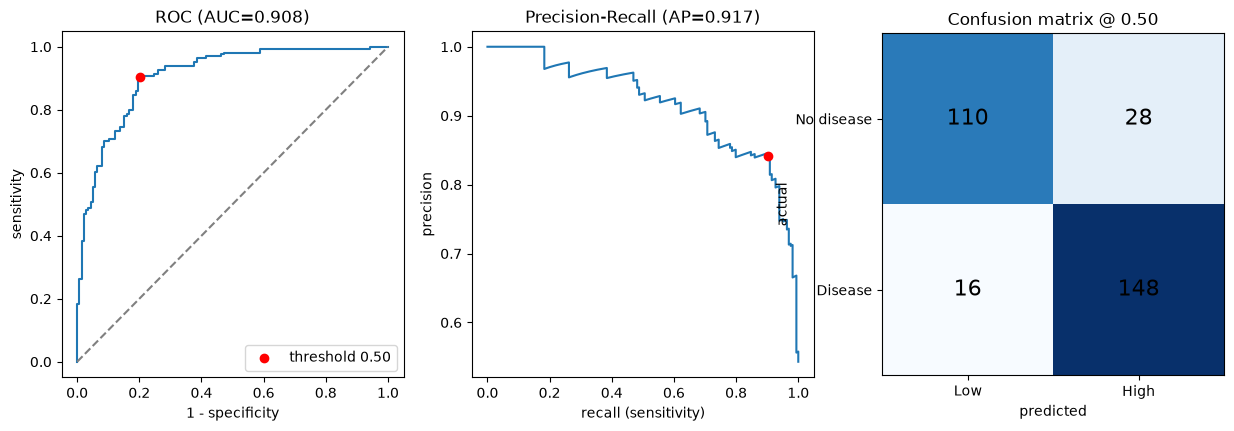

Per 1000 patients (dataset is ~54% sick, far above a real screening population):
{'flagged': 583, 'caught': 490, 'false_alarms': 93, 'missed': 53}


In [24]:
pred = (p >= THR).astype(int)
cm = confusion_matrix(y_true, pred)
fpr, tpr, _ = roc_curve(y_true, p)
prec, rec, _ = precision_recall_curve(y_true, p)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "--", c="grey")
ax[0].scatter([1 - best.specificity], [best.sensitivity], c="red", zorder=3, label=f"threshold {THR:.2f}")
ax[0].set(xlabel="1 - specificity", ylabel="sensitivity",
          title=f"ROC (AUC={roc_auc_score(y_true, p):.3f})"); ax[0].legend()
ax[1].plot(rec, prec); ax[1].scatter([best.sensitivity], [best.precision], c="red", zorder=3)
ax[1].set(xlabel="recall (sensitivity)", ylabel="precision",
          title=f"Precision-Recall (AP={average_precision_score(y_true, p):.3f})")
ax[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[2].text(j, i, v, ha="center", va="center", fontsize=16)
ax[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Low", "High"],
          yticklabels=["No disease", "Disease"], xlabel="predicted", ylabel="actual",
          title=f"Confusion matrix @ {THR:.2f}")
fig.savefig(ARTIFACTS / "eval_curves.png", dpi=150, bbox_inches="tight")
plt.show()

tn_, fp_, fn_, tp_ = cm.ravel(); N = len(y_true)
print("Per 1000 patients (dataset is ~54% sick, far above a real screening population):")
print(dict(flagged=round((tp_+fp_)/N*1000), caught=round(tp_/N*1000),
           false_alarms=round(fp_/N*1000), missed=round(fn_/N*1000)))

In [25]:
# Error analysis: who does the model get wrong?
res = X.copy()
res["target"], res["proba"], res["pred"] = y_true, p.round(3), pred

fn_df = res[(res.target == 1) & (res.pred == 0)].sort_values("proba", ascending=False)   # missed
fp_df = res[(res.target == 0) & (res.pred == 1)].sort_values("proba", ascending=False)   # false alarms
boundary = res[(res.proba - THR).abs() <= 0.05]                                           # uncertain
print(f"Missed (FN): {len(fn_df)} | False alarms (FP): {len(fp_df)} | Near threshold: {len(boundary)}")

cols = ["age", "sex", "cp", "thalach", "oldpeak", "exang", "ca", "thal"]
print("\nSick patients: average profile of missed (pred=0) vs caught (pred=1)")
print(res[res.target == 1].groupby("pred")[cols].mean().round(2))
fn_df.head(10)

Missed (FN): 16 | False alarms (FP): 28 | Near threshold: 12

Sick patients: average profile of missed (pred=0) vs caught (pred=1)
        age   sex    cp  thalach  oldpeak  exang    ca  thal
pred                                                        
0     57.50  0.94  1.19   142.50     1.26   0.38  0.88  2.44
1     52.05  0.52  1.39   160.09     0.51   0.11  0.28  2.09


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,proba,pred
86,68,1,2,118,277,0,1,151,0,1.0,2,1,3,1,0.487,0
150,66,1,0,160,228,0,0,138,0,2.3,2,0,1,1,0.432,0
91,57,1,0,132,207,0,1,168,1,0.0,2,0,3,1,0.419,0
100,42,1,3,148,244,0,0,178,0,0.8,2,2,2,1,0.412,0
20,59,1,0,135,234,0,1,161,0,0.5,1,0,3,1,0.401,0
83,52,1,3,152,298,1,1,178,0,1.2,1,0,3,1,0.401,0
120,64,0,0,130,303,0,1,122,0,2.0,1,2,2,1,0.320,0
42,45,1,0,104,208,0,0,148,1,3.0,1,0,2,1,0.301,0
138,57,1,0,110,201,0,1,126,1,1.5,1,0,1,1,0.288,0
34,51,1,3,125,213,0,0,125,1,1.4,2,1,2,1,0.285,0


In [26]:
# Permutation importance across CV folds (association with the outcome, not causation)
imps = []
for tr, va in skf.split(X, y):
    m = clone(final_soft.best_estimator_).fit(X.iloc[tr], y.iloc[tr])
    r = permutation_importance(m, X.iloc[va], y.iloc[va], scoring="roc_auc",
                               n_repeats=10, random_state=SEED, n_jobs=-1)
    imps.append(r.importances_mean)

importance = pd.Series(np.mean(imps, axis=0), index=X.columns).sort_values(ascending=False)
importance.round(3)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

ca          0.046
thal        0.024
cp          0.021
thalach     0.012
oldpeak     0.011
sex         0.010
slope       0.003
trestbps    0.003
exang       0.002
age         0.000
fbs        -0.001
restecg    -0.001
chol       -0.001
dtype: float64

In [27]:
# Save the model and its metadata (FastAPI will load these in Week 9)
MODEL_DIR = ARTIFACTS / "models"; MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "model_m1.0.0.joblib"
joblib.dump(final_soft.best_estimator_, model_path)      # already fit on all 302 patients
sha = hashlib.sha256(model_path.read_bytes()).hexdigest()

meta = {
    "model_name": "Voting Classifier Heart Disease Risk Flag",
    "model_version": "m1.0.0",
    "voting_strategy": "soft",
    "training_date": datetime.date.today().isoformat(),
    "n_training_rows": int(len(y)), "seed": SEED,
    "hyperparameters": final_soft.best_params_,
    "threshold": THR,
    "threshold_rationale": f"Maximise specificity subject to sensitivity >= {TARGET_SENS} on out-of-fold predictions.",
    "metrics_at_threshold_oof": {k: float(best[k]) for k in ["sensitivity", "specificity", "precision", "f1"]},
    "metrics_honest_check": {k: float(v) for k, v in honest.items()},
    "roc_auc_oof": float(roc_auc_score(y_true, p)),
    "nested_cv_summary": json.loads(summary_soft.to_json()),
    "artifact_sha256": sha,
}
(MODEL_DIR / "model_m1.0.0.json").write_text(json.dumps(meta, indent=2, default=str))
sweep.to_csv(ARTIFACTS / "week8_threshold_sweep.csv", index=False)
importance.to_csv(ARTIFACTS / "week8_permutation_importance.csv")
print("saved", model_path.name, "| sha256", sha[:12])

saved model_m1.0.0.joblib | sha256 1c960f3ca489
